# Wrocław Housing Price Model: Python replication

Replication of the ARDL/OLS model from my master's thesis, originally
estimated in Gretl. The notebook rebuilds the full pipeline: loading data
from the SQLite database, harmonising quarter formats, building lags and
dummy variables, estimating the model, running residual diagnostics and
producing a dynamic forecast for 2026 Q1–Q2.

**Result:** all 25 coefficients reproduce Gretl's signs and significance;
the 2026 forecast differs from the thesis by ~0.03%.

## 1. Setup

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.diagnostic import (
    het_breuschpagan,
    acorr_breusch_godfrey,
    breaks_cusumolsresid,
)
from scipy import stats

## 2. Load data from SQLite
Queries are the same as in sql/queries.sql. Cleaning (decimal commas, thousand separators, CPI series selection) happens in SQL.

In [2]:
conn = sqlite3.connect("../sql/housing_model.db")

In [3]:
query_cpi = """
SELECT "Rok" AS year, "Kwartał" AS quarter,
        CAST(REPLACE("Wartość", ',', '.') AS REAL) AS cpi_index
FROM cpi
WHERE "Sposób prezentacji" LIKE 'Analogiczny okres%'
ORDER BY "Rok", "Kwartał";
"""
df_cpi = pd.read_sql_query(query_cpi, conn)
df_cpi.head()

,year,quarter,cpi_index
0,1995,I kwartał,133.0
1,1995,II kwartał,131.6
2,1995,III kwartał,125.8
3,1995,IV kwartał,122.0
4,1996,I kwartał,120.6


In [4]:
query_housing = """
SELECT "Kwartał",
       CAST(REPLACE(REPLACE(REPLACE("Cena", CHAR(160), ''), ' ', ''), ',', '.') AS REAL) AS price
FROM housing_prices
ORDER BY
  CAST(SUBSTR("Kwartał", -4) AS INTEGER),
  CASE SUBSTR("Kwartał", 1, INSTR("Kwartał", ' ') - 1)
    WHEN 'I'    THEN 1
    WHEN 'II'   THEN 2
    WHEN 'III'  THEN 3
    WHEN 'IV'   THEN 4
  END;
"""
df_housing = pd.read_sql_query(query_housing, conn)
df_housing.head()

,Kwartał,price
0,I 2008,5268.0
1,II 2008,5349.0
2,III 2008,5891.0
3,IV 2008,5513.0
4,I 2009,5218.0


In [5]:
query_unemployment = """
SELECT
  year,
  CASE
    WHEN month IN (1,2,3)   THEN 1
    WHEN month IN (4,5,6)   THEN 2
    WHEN month IN (7,8,9)   THEN 3
    WHEN month IN (10,11,12) THEN 4
  END AS quarter,
  ROUND(AVG(CAST(unemployment_rate AS REAL)), 2) AS avg_unemployment_rate
FROM unemployment
WHERE methodology_variant IS NOT 'b_new_methodology'
  AND unemployment_rate IS NOT NULL AND unemployment_rate != ''
GROUP BY year, quarter
ORDER BY year, quarter;
"""
df_unemployment = pd.read_sql_query(query_unemployment, conn)
df_unemployment.head()

,year,quarter,avg_unemployment_rate
0,1990,1,0.87
1,1990,2,2.47
2,1990,3,4.43
3,1990,4,5.97
4,1991,1,6.83


In [6]:
query_gdp = """
SELECT "Kwartał",
       CAST(REPLACE(REPLACE(REPLACE("Wartość", CHAR(160), ''), ' ', ''), ',', '.') AS REAL) AS gdp_growth_pct
FROM gdp
ORDER BY
  CAST(SUBSTR("Kwartał", 1, 4) AS INTEGER),
  CAST(SUBSTR("Kwartał", -1) AS INTEGER);
"""
df_gdp = pd.read_sql_query(query_gdp, conn)
df_gdp.head()

,Kwartał,gdp_growth_pct
0,2008 Q1,6.0
1,2008 Q2,5.8
2,2008 Q3,4.9
3,2008 Q4,3.0
4,2009 Q1,2.2


In [7]:
query_wibor = """
SELECT "Kwartał",
       CAST(REPLACE(REPLACE(REPLACE("Wartość (%)", CHAR(160), ''), ' ', ''), ',', '.') AS REAL) AS wibor_3m_pct
FROM wibor3m
ORDER BY
  CAST(SUBSTR("Kwartał", -4) AS INTEGER),
  CAST(SUBSTR("Kwartał", 2, 1) AS INTEGER);
"""
df_wibor = pd.read_sql_query(query_wibor, conn)
df_wibor.head()

,Kwartał,wibor_3m_pct
0,Q1 2008,5.8
1,Q2 2008,6.5
2,Q3 2008,6.6
3,Q4 2008,6.5
4,Q1 2009,4.8


In [8]:
for name, df in [("cpi", df_cpi), ("housing", df_housing),("unemployment", df_unemployment),("gdp", df_gdp),("wibor", df_wibor)]:
    print(name, df.shape)

cpi (128, 3)
housing (72, 2)
unemployment (147, 3)
gdp (72, 2)
wibor (72, 2)


## 3. Harmonise quarter formats
Each source used a different quarter label ("I 2008", "2008 Q1", "Q1 2008", "I kwartał"). All are converted to numeric year/quarter keys.

In [9]:
roman_to_quarter = {"I": 1, "II": 2, "III": 3, "IV": 4}

In [10]:
df_housing[["roman_q", "year"]] = df_housing["Kwartał"].str.split(" ", expand=True)
df_housing["quarter"] = df_housing["roman_q"].map(roman_to_quarter)
df_housing["year"] = df_housing["year"].astype(int)
df_housing = df_housing.drop(columns=["Kwartał", "roman_q"])



In [11]:
df_cpi["quarter"] = df_cpi["quarter"].str.replace(" kwartał", "", regex=False).map(roman_to_quarter)

In [12]:
df_gdp[["year", "q_label"]] = df_gdp["Kwartał"].str.split(" ", expand=True)
df_gdp["year"] = df_gdp["year"].astype(int)
df_gdp["quarter"] = df_gdp["q_label"].str.replace("Q", "", regex=False).astype(int)
df_gdp = df_gdp.drop(columns=["Kwartał", "q_label"])

In [13]:
df_wibor[["q_label", "year"]] = df_wibor["Kwartał"].str.split(" ", expand=True)
df_wibor["year"] = df_wibor["year"].astype(int)
df_wibor["quarter"] = df_wibor["q_label"].str.replace("Q", "", regex=False).astype(int)
df_wibor = df_wibor.drop(columns=["Kwartał", "q_label"])

In [14]:
for name, df in [("cpi", df_cpi), ("housing", df_housing), ("unemployment", df_unemployment), ("gdp", df_gdp), ("wibor", df_wibor)]:
    print(name, df[["year", "quarter"]].dtypes.tolist(), df["year"].min(), "-", df["year"].max())

cpi [dtype('int64'), dtype('int64')] 1995 - 2026
housing [dtype('int64'), dtype('int64')] 2008 - 2025
unemployment [dtype('int64'), dtype('int64')] 1990 - 2026
gdp [dtype('int64'), dtype('int64')] 2008 - 2025
wibor [dtype('int64'), dtype('int64')] 2008 - 2025


## 4. Merge into one dataset

In [15]:
df = df_housing.merge(df_cpi[["year", "quarter", "cpi_index"]], on=["year", "quarter"], how="left")
df = df.merge(df_unemployment[["year", "quarter", "avg_unemployment_rate"]], on=["year", "quarter"], how="left")
df = df.merge(df_gdp[["year", "quarter", "gdp_growth_pct"]], on=["year", "quarter"], how="left")
df = df.merge(df_wibor[["year", "quarter", "wibor_3m_pct"]], on=["year", "quarter"], how="left")
df = df.sort_values(["year", "quarter"]).reset_index(drop=True)
df.head()

,price,year,quarter,cpi_index,avg_unemployment_rate,gdp_growth_pct,wibor_3m_pct
0,5268.0,2008,1,104.1,11.23,6.0,5.8
1,5349.0,2008,2,104.3,9.83,5.8,6.5
2,5891.0,2008,3,104.7,9.07,4.9,6.6
3,5513.0,2008,4,103.8,9.13,3.0,6.5
4,5218.0,2009,1,103.3,10.80,2.2,4.8


In [16]:
df.isna().sum()

price                    0
year                     0
quarter                  0
cpi_index                0
avg_unemployment_rate    0
gdp_growth_pct           0
wibor_3m_pct             0
dtype: int64

In [17]:
df = df.rename(columns={
    "price": "Cena_Wroclaw",
    "cpi_index": "Inflacja",
    "avg_unemployment_rate": "Bezrobocie",
    "gdp_growth_pct": "PKB",
    "wibor_3m_pct": "Stopa_WIBOR",
})
df.head()

,Cena_Wroclaw,year,quarter,Inflacja,Bezrobocie,PKB,Stopa_WIBOR
0,5268.0,2008,1,104.1,11.23,6.0,5.8
1,5349.0,2008,2,104.3,9.83,5.8,6.5
2,5891.0,2008,3,104.7,9.07,4.9,6.6
3,5513.0,2008,4,103.8,9.13,3.0,6.5
4,5218.0,2009,1,103.3,10.80,2.2,4.8


## 5. Units, dependent variable and dummies
Gretl used fractions, not percentages (CPI index 104.1 → 0.041). The dependent variable is the quarterly log growth of prices.

In [18]:
model_df = df.copy()
model_df["Inflacja"] = (model_df["Inflacja"] - 100) / 100
model_df["Bezrobocie"] = model_df["Bezrobocie"] / 100
model_df["PKB"] = model_df["PKB"] / 100
model_df["Stopa_WIBOR"] = model_df["Stopa_WIBOR"] / 100

In [19]:
model_df["d_l_Cena_Wroclaw"] = np.log(model_df["Cena_Wroclaw"]).diff()

In [20]:
period = model_df["year"] * 10 + model_df["quarter"]

def make_dummy(start, end):
    return ((period >= start) & (period <= end)).astype(int)

model_df["boom_2008"] = make_dummy(20082, 20091)
model_df["kryzys_euro1"] = make_dummy(20113, 20134)
model_df["covid_szok"] = make_dummy(20202, 20202)
model_df["bezpieczny_kredyt"] = make_dummy(20233, 20234)
model_df["okres_popandemiczny"] = make_dummy(20214, 20224)
model_df["wzrost_2019"] = make_dummy(20191, 20192)

In [21]:
dummy_cols = ["boom_2008", "kryzys_euro1", "covid_szok", "bezpieczny_kredyt", "okres_popandemiczny", "wzrost_2019"]

print(model_df[dummy_cols].sum())
model_df[["Cena_Wroclaw", "d_l_Cena_Wroclaw"]].head(3)

boom_2008               4
kryzys_euro1           10
covid_szok              1
bezpieczny_kredyt       2
okres_popandemiczny     5
wzrost_2019             2
dtype: int64


,Cena_Wroclaw,d_l_Cena_Wroclaw
0,5268.0,NaN
1,5349.0,0.015259
2,5891.0,0.096516


## 6. Model specification and estimation
Final specification after stepwise elimination in Gretl (5% level). Estimation sample: 2009 Q2 – 2025 Q4, n = 67.

In [22]:
final_terms = [
    ("Inflacja", 1), ("Inflacja", 4),
    ("Bezrobocie", 0), ("Bezrobocie", 1),
    ("PKB", 1), ("PKB", 2), ("PKB", 3),
    ("Stopa_WIBOR", 3), ("Stopa_WIBOR", 4),
    ("boom_2008", 3), ("boom_2008", 4),
    ("kryzys_euro1", 1),
    ("covid_szok", 0), ("covid_szok", 1), ("covid_szok", 3), ("covid_szok", 4),
    ("bezpieczny_kredyt", 0), ("bezpieczny_kredyt", 3),
    ("okres_popandemiczny", 0), ("okres_popandemiczny", 1), ("okres_popandemiczny", 2),
    ("wzrost_2019", 1), ("wzrost_2019", 4),
    ("d_l_Cena_Wroclaw", 1), ("d_l_Cena_Wroclaw", 2),
]

In [23]:
X = pd.DataFrame(index=model_df.index)

for variable, lag in final_terms:
    name = variable if lag == 0 else f"{variable}_{lag}"
    X[name] = model_df[variable].shift(lag)

X = sm.add_constant(X)
Y = model_df["d_l_Cena_Wroclaw"]
mask = period >= 20092

In [24]:
model = sm.OLS(Y[mask], X[mask]).fit()

print(f"n = {int(model.nobs)}, R2 = {model.rsquared:.4f}, "
      f"adj R2 = {model.rsquared_adj:.4f}, sigma = {model.scale ** 0.5:.6f}")

n = 67, R2 = 0.8214, adj R2 = 0.7125, sigma = 0.017378


In [25]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:       d_l_Cena_Wroclaw   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.712
Method:                 Least Squares   F-statistic:                     7.541
Date:                Sun, 18 Oct 2026   Prob (F-statistic):           9.42e-09
Time:                        19:20:06   Log-Likelihood:                 192.91
No. Observations:                  67   AIC:                            -333.8
Df Residuals:                      41   BIC:                            -276.5
Df Model:                          25                                         
Covariance Type:            nonrobust                                         
=========================================================================================
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                     0.0626      0.017      3.749      0.001       0.029       0.096
Inflacja_1                1.0602      0.194      5.472      0.000       0.669       1.451
Inflacja_4                0.3773      0.161      2.342      0.024       0.052       0.703
Bezrobocie               -1.6652      0.490     -3.399      0.002      -2.654      -0.676
Bezrobocie_1              1.6821      0.465      3.616      0.001       0.743       2.622
PKB_1                    -0.8197      0.202     -4.051      0.000      -1.228      -0.411
PKB_2                     0.8412      0.168      5.011      0.000       0.502       1.180
PKB_3                    -0.8164      0.176     -4.650      0.000      -1.171      -0.462
Stopa_WIBOR_3            -6.6601      0.883     -7.540      0.000      -8.444      -4.876
Stopa_WIBOR_4             5.2111      0.834      6.246      0.000       3.526       6.896
boom_2008_3              -0.1128      0.027     -4.245      0.000      -0.166      -0.059
boom_2008_4               0.0566      0.022      2.631      0.012       0.013       0.100
kryzys_euro1_1           -0.0375      0.009     -4.070      0.000      -0.056      -0.019
covid_szok               -0.1062      0.026     -4.049      0.000      -0.159      -0.053
covid_szok_1             -0.1188      0.033     -3.603      0.001      -0.185      -0.052
covid_szok_3             -0.1832      0.032     -5.787      0.000      -0.247      -0.119
covid_szok_4             -0.0845      0.023     -3.681      0.001      -0.131      -0.038
bezpieczny_kredyt        -0.0597      0.021     -2.887      0.006      -0.102      -0.018
bezpieczny_kredyt_3       0.0528      0.017      3.057      0.004       0.018       0.088
okres_popandemiczny      -0.0865      0.020     -4.254      0.000      -0.128      -0.045
okres_popandemiczny_1     0.1507      0.025      5.987      0.000       0.100       0.201
okres_popandemiczny_2    -0.0988      0.022     -4.506      0.000      -0.143      -0.055
wzrost_2019_1             0.0430      0.014      3.114      0.003       0.015       0.071
wzrost_2019_4             0.0627      0.019      3.326      0.002       0.025       0.101
d_l_Cena_Wroclaw_1       -0.6722      0.102     -6.581      0.000      -0.878      -0.466
d_l_Cena_Wroclaw_2       -0.4181      0.092     -4.542      0.000      -0.604      -0.232
==============================================================================
Omnibus:                        2.683   Durbin-Watson:                   2.261
Prob(Omnibus):                  0.261   Jarque-Bera (JB):                1.943
Skew:                           0.388   Prob(JB):                        0.379
Kurtosis:                       3.306   Cond. No.                         598.
==============================================================================

## 7. Comparison with Gretl
Small differences come from the input data: 9 of 72 unemployment quarters differ from the values used in the thesis (max 0.2 pp). Run on Gretl's original data, this code reproduces the thesis coefficients exactly.

In [26]:
gretl_coef = {
    "const": 0.0633, "Inflacja_1": 1.0543, "Inflacja_4": 0.3773,
    "Bezrobocie": -1.7004, "Bezrobocie_1": 1.7130,
    "PKB_1": -0.8213, "PKB_2": 0.8476, "PKB_3": -0.8290,
    "Stopa_WIBOR_3": -6.5842, "Stopa_WIBOR_4": 5.1391,
    "boom_2008_3": -0.1152, "boom_2008_4": 0.0586,
    "kryzys_euro1_1": -0.0373,
    "covid_szok": -0.1059, "covid_szok_1": -0.1188,
    "covid_szok_3": -0.1835, "covid_szok_4": -0.0846,
    "bezpieczny_kredyt": -0.0594, "bezpieczny_kredyt_3": 0.0529,
    "okres_popandemiczny": -0.0852, "okres_popandemiczny_1": 0.1490,
    "okres_popandemiczny_2": -0.0983,
    "wzrost_2019_1": 0.0431, "wzrost_2019_4": 0.0629,
    "d_l_Cena_Wroclaw_1": -0.6753, "d_l_Cena_Wroclaw_2": -0.4209,
}

comparison = pd.DataFrame({"gretl": pd.Series(gretl_coef), "python": model.params})
comparison["różnica"] = comparison["python"] - comparison["gretl"]

print("zgodność znaków:", (np.sign(comparison["gretl"]) == np.sign(comparison["python"])).all())
print("największa różnica bezwzględna:", comparison["różnica"].abs().max().round(4))
comparison.round(4)

zgodność znaków: True
największa różnica bezwzględna: 0.0759


,gretl,python,różnica
const,0.0633,0.0626,-0.0007
Inflacja_1,1.0543,1.0602,0.0059
Inflacja_4,0.3773,0.3773,0.0000
Bezrobocie,-1.7004,-1.6652,0.0352
Bezrobocie_1,1.7130,1.6821,-0.0309
PKB_1,-0.8213,-0.8197,0.0016
PKB_2,0.8476,0.8412,-0.0064
PKB_3,-0.8290,-0.8164,0.0126
Stopa_WIBOR_3,-6.5842,-6.6601,-0.0759
Stopa_WIBOR_4,5.1391,5.2111,0.0720


## 8. Residual diagnostics
H0 not rejected in all tests at the 5% level: homoskedasticity (Breusch-Pagan), no autocorrelation up to order 4 (Breusch-Godfrey, F version), normality (Shapiro-Wilk).

In [27]:
lm_bp, p_bp, f_bp, fp_bp = het_breuschpagan(model.resid, model.model.exog, robust=False)
print(f"Breusch-Pagan: LM = {lm_bp:.4f}, p = {p_bp:.6f}")

Breusch-Pagan: LM = 22.8441, p = 0.586667


In [28]:
for k in (1, 4):
    lm_bg, p_bg, f_bg, fp_bg = acorr_breusch_godfrey(model, nlags=k, result_object=False)
    print(f"Breusch-Godfrey, rząd {k}: LMF = {f_bg:.4f}, p = {fp_bg:.6f}")

Breusch-Godfrey, rząd 1: LMF = 2.1328, p = 0.151991
Breusch-Godfrey, rząd 4: LMF = 1.8360, p = 0.142632


In [29]:
w_sw, p_sw = stats.shapiro(model.resid)
print(f"Shapiro-Wilk: W = {w_sw:.4f}, p = {p_sw:.6f}")

Shapiro-Wilk: W = 0.9802, p = 0.363054


## 9. Parameter stability (OLS-CUSUM)
OLS-residual version; the recursive-residual CUSUM is not computable here because the dummy variables make the initial regressor matrix singular.

OLS-CUSUM: statystyka = 0.3220, p = 0.9999
wartości krytyczne (poziom %, wartość): [(1, 1.63), (5, 1.36), (10, 1.22)]


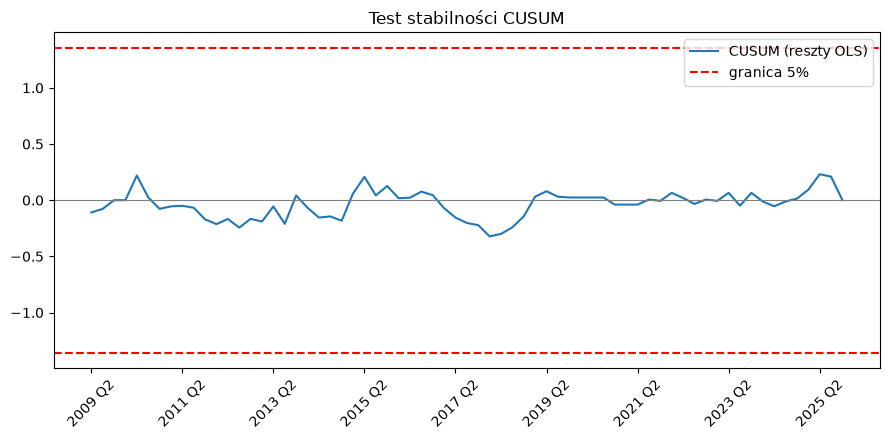

In [30]:
k = int(model.df_model) + 1
stat, p_cusum, crit = breaks_cusumolsresid(model.resid, ddof=k)
print(f"OLS-CUSUM: statystyka = {stat:.4f}, p = {p_cusum:.4f}")
print("wartości krytyczne (poziom %, wartość):", crit)

resid = model.resid.values
n = len(resid)
sigma = np.sqrt((resid ** 2).sum() / (n - k))
cusum = np.cumsum(resid) / (sigma * np.sqrt(n))
labels = [f"{y} Q{q}" for y, q in zip(model_df.loc[mask, "year"], model_df.loc[mask, "quarter"])]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(range(n), cusum, label="CUSUM (reszty OLS)")
ax.axhline(1.358, color="red", linestyle="--", label="granica 5%")
ax.axhline(-1.358, color="red", linestyle="--")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(range(0, n, 8))
ax.set_xticklabels(labels[::8], rotation=45)
ax.set_title("Test stabilności CUSUM")
ax.legend()
fig.tight_layout()
plt.show()

In [31]:
print(df_cpi[df_cpi["year"] == 2026])
print(df_unemployment[(df_unemployment["year"] == 2026) & (df_unemployment["quarter"] <= 2)])

     year  quarter  cpi_index
124  2026        1      102.4
125  2026        2        NaN
126  2026        3        NaN
127  2026        4        NaN
     year  quarter  avg_unemployment_rate
144  2026        1                   6.07
145  2026        2                   5.90


## 10. Dynamic forecast for 2026 Q1–Q2

In [32]:
future = pd.DataFrame({
    "year": [2026, 2026],
    "quarter": [1, 2],
    "Inflacja": [0.024, np.nan],
    "Bezrobocie": [0.0607, 0.0590],
    "PKB": [0.035, np.nan],
})
ext = pd.concat([model_df, future], ignore_index=True)
ext[dummy_cols] = ext[dummy_cols].fillna(0)

In [33]:
def build_X(data):
    X_ = pd.DataFrame(index=data.index)
    for variable, lag in final_terms:
        name = variable if lag == 0 else f"{variable}_{lag}"
        X_[name] = data[variable].shift(lag)
    return sm.add_constant(X_)

i1 = ext.index[(ext["year"] == 2026) & (ext["quarter"] == 1)][0]

X1 = build_X(ext).loc[[i1], model.params.index]
f1 = float(model.predict(X1).iloc[0])
ext.loc[i1, "d_l_Cena_Wroclaw"] = f1

X2 = build_X(ext).loc[[i1 + 1], model.params.index]
f2 = float(model.predict(X2).iloc[0])
print("braki w danych wyjściowych:", X1.isna().sum(), X2.isna().sum().sum())

braki w danych wyjściowych: const                    0
Inflacja_1               0
Inflacja_4               0
Bezrobocie               0
Bezrobocie_1             0
PKB_1                    0
PKB_2                    0
PKB_3                    0
Stopa_WIBOR_3            0
Stopa_WIBOR_4            0
boom_2008_3              0
boom_2008_4              0
kryzys_euro1_1           0
covid_szok               0
covid_szok_1             0
covid_szok_3             0
covid_szok_4             0
bezpieczny_kredyt        0
bezpieczny_kredyt_3      0
okres_popandemiczny      0
okres_popandemiczny_1    0
okres_popandemiczny_2    0
wzrost_2019_1            0
wzrost_2019_4            0
d_l_Cena_Wroclaw_1       0
d_l_Cena_Wroclaw_2       0
dtype: int64 0


In [34]:
sigma = model.scale ** 0.5
phi1 = model.params["d_l_Cena_Wroclaw_1"]
se1, se2 = sigma, sigma * np.sqrt(1 + phi1 ** 2)
t_crit = stats.t.ppf(0.975, model.df_resid)

last_price = ext.loc[i1 - 1, "Cena_Wroclaw"]
price1 = last_price * np.exp(f1)
price2 = price1 * np.exp(f2)
lo1, hi1 = last_price * np.exp(f1 - t_crit * se1), last_price * np.exp(f1 + t_crit * se1)
lo2, hi2 = price1 * np.exp(f2 - t_crit * se2), price1 * np.exp(f2 + t_crit * se2)

print(f"2026 Q1: wzrost log = {f1:.4f}, cena = {price1:,.0f} zł/m2, SE = {se1:.6f}, 95% przedział: {lo1:,.0f} - {hi1:,.0f}")
print(f"2026 Q2: wzrost log = {f2:.4f}, cena = {price2:,.0f} zł/m2, SE = {se2:.6f}, 95% przedział: {lo2:,.0f} - {hi2:,.0f}")

2026 Q1: wzrost log = 0.0580, cena = 14,901 zł/m2, SE = 0.017378, 95% przedział: 14,387 - 15,433
2026 Q2: wzrost log = 0.0101, cena = 15,052 zł/m2, SE = 0.020939, 95% przedział: 14,429 - 15,702


## 11. Export

In [35]:
model_df.to_csv("../data/processed/model_dataset.csv", index=False)

forecast = pd.DataFrame({
    "year": [2026, 2026],
    "quarter": [1, 2],
    "log_growth": [f1, f2],
    "price": [price1, price2],
    "price_lower_95": [lo1, lo2],
    "price_upper_95": [hi1, hi2],
})
forecast.to_csv("../data/processed/forecast_2026.csv", index=False)
forecast.round(4)

,year,quarter,log_growth,price,price_lower_95,price_upper_95
0,2026,1,0.0580,14901.0590,14387.1740,15433.2992
1,2026,2,0.0101,15052.0185,14428.7944,15702.1616


In [36]:
conn.close()

## 12. Dashboard export

In [37]:
def quarter_start(data):
    parts = pd.DataFrame({
        "year": data["year"],
        "month": (data["quarter"] - 1) * 3 + 1,
        "day": 1,
    })
    return pd.to_datetime(parts)


In [38]:
history = model_df[["year", "quarter", "Cena_Wroclaw"]].rename(
    columns={"Cena_Wroclaw": "price_actual"}
)
fc = forecast.rename(columns={
    "price": "price_forecast",
    "price_lower_95": "lower_95",
    "price_upper_95": "upper_95",
})

chart = pd.concat([history, fc], ignore_index=True)

last = chart.index[(chart["year"] == 2025) & (chart["quarter"] == 4)][0]
chart.loc[last, ["price_forecast", "lower_95", "upper_95"]] = chart.loc[last, "price_actual"]

chart.insert(0, "date", quarter_start(chart))
chart = chart.drop(columns=["log_growth"])
chart.to_csv("../data/processed/dashboard_prices.csv", index=False)
chart.tail(4)

,date,year,quarter,price_actual,price_forecast,lower_95,upper_95
70,2025-07-01,2025,3,14529.0,NaN,NaN,NaN
71,2025-10-01,2025,4,14062.0,14062.000000,14062.000000,14062.000000
72,2026-01-01,2026,1,NaN,14901.059041,14387.173998,15433.299173
73,2026-04-01,2026,2,NaN,15052.018533,14428.794444,15702.161591


In [39]:
macro = model_df[["year", "quarter", "Inflacja", "Bezrobocie", "PKB", "Stopa_WIBOR"]].copy()
macro[["Inflacja", "Bezrobocie", "PKB", "Stopa_WIBOR"]] *= 100
macro = macro.rename(columns={
    "Inflacja": "inflation_pct",
    "Bezrobocie": "unemployment_pct",
    "PKB": "gdp_growth_pct",
    "Stopa_WIBOR": "wibor_3m_pct",
})
macro.insert(0, "date", quarter_start(macro))
macro.to_csv("../data/processed/dashboard_macro.csv", index=False)
macro.head(3)

,date,year,quarter,inflation_pct,unemployment_pct,gdp_growth_pct,wibor_3m_pct
0,2008-01-01,2008,1,4.1,11.23,6.0,5.8
1,2008-04-01,2008,2,4.3,9.83,5.8,6.5
2,2008-07-01,2008,3,4.7,9.07,4.9,6.6
